<a href="https://colab.research.google.com/github/itspratigya/query-by-image-vos-and-tracking/blob/pratigya_week1_env_setup/query_by_image_vos_tracking_final_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Query-by-Image Video Object Search and Tracking:

**Before running:** Runtime -> Change runtime type -> Hardware accelerator -> **T4 GPU** -> Save.

## WEEK1: Set up DINOv2, FFmpeg/frame sampling, and SAM candidate generation


### Step 1.1: Environment Setup

In [1]:
!nvidia-smi

import sys, torch

print("python:", sys.version.split()[0])
print("torch :", torch.__version__, "| cuda available:", torch.cuda.is_available())

Mon Nov 16 19:18:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os, subprocess

SAM2_DIR   = "/content/sam2"
CKPT_DIR   = f"{SAM2_DIR}/checkpoints"
DRIVE_ROOT = "/content/drive/MyDrive"
DRIVE_CKPT = f"{DRIVE_ROOT}/qbi/checkpoints"          # checkpoint copies kept on Drive so they are not re-downloaded
DAVIS      = f"{DRIVE_ROOT}/data/DAVIS"               # this is where DAVIS folder is on Drive
IMG_DIR  = f"{DAVIS}/JPEGImages/480p"
ANN_DIR  = f"{DAVIS}/Annotations/480p"
WORK       = "/content/work"                          # temporary files (lost when the session ends)
WORK_OUT = f"{WORK}/out"
OUT        = f"{DRIVE_ROOT}/out"
PAIR_DIR = f"{WORK_OUT}/pairs"                   # results you want to keep
os.makedirs(WORK, exist_ok=True)

In [3]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


### Step 1.2: Data Setup - DAVIS 2017
Setup Datasets locally and add only what's nneded for test in drive.

MOSE consists of real-world complex scenarios. We will prepare MOSE in later weeks.

Train-test split
- Training set: DAVIS train (60 videos)
- Testing set: DAVIS val (30 videos)
- MOSE will be added to both in later weeks.

Storage note
Datasets take a lot of space and Google Drive has only 15 GB free in total. We keep only the DAVIS and MOSE subsets needed on Drive.

In [4]:
# Use DAVIS from Drive.
print("DAVIS folder exists:", os.path.exists(DAVIS))
print("Contents:", os.listdir(DAVIS))
print(sorted(os.listdir(f"{DAVIS}/JPEGImages/480p"))[:5], "...")

DAVIS folder exists: True
Contents: ['Annotations', 'JPEGImages', 'ImageSets', 'outputs']
['bear', 'bike-packing', 'blackswan', 'bmx-bumps', 'bmx-trees'] ...


### Step 2.1: Download and install SAM 2.1

In [5]:
# get SAM 2 and install it
!git clone https://github.com/facebookresearch/sam2.git
%cd {SAM2_DIR}
!pip install -e . -q

Cloning into 'sam2'...
remote: Enumerating objects: 1107, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 1107 (delta 13), reused 7 (delta 7), pack-reused 1089 (from 2)
Receiving objects: 100% (1107/1107), 134.85 MiB | 22.74 MiB/s, done.
Resolving deltas: 100% (385/385), done.
/content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for SAM-2 (pyproject.toml) ... done


### Step 2.2: SAM 2.1 checkpoints
Only `sam2.1_hiera_small.pt` (candidates) and `sam2.1_hiera_large.pt` (query image and tracking) are needed.

In [6]:
%cd {CKPT_DIR}

/content/sam2/checkpoints


In [7]:
!bash download_ckpts.sh

--2026-11-16 19:23:53--  https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_tiny.pt
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 3.163.189.51, 3.163.189.14, 3.163.189.96, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|3.163.189.51|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 156008466 (149M) [application/vnd.snesdev-page-table]
Saving to: ‘sam2.1_hiera_tiny.pt’

sam2.1_hiera_tiny.p 100%[===================>] 148.78M   227MB/s    in 0.7s    

2026-11-16 19:23:54 (227 MB/s) - ‘sam2.1_hiera_tiny.pt’ saved [156008466/156008466]

--2026-11-16 19:23:54--  https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 3.163.189.51, 3.163.189.14, 3.163.189.96, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|3.163.189.51|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 184416285 (176M) [applicat

In [8]:
!ls -lh

total 1.5G
-rwxr-xr-x 1 root root 2.6K Nov 16 19:19 download_ckpts.sh
-rw-r--r-- 1 root root 309M Sep 29  2024 sam2.1_hiera_base_plus.pt
-rw-r--r-- 1 root root 857M Sep 29  2024 sam2.1_hiera_large.pt
-rw-r--r-- 1 root root 176M Sep 29  2024 sam2.1_hiera_small.pt
-rw-r--r-- 1 root root 149M Sep 29  2024 sam2.1_hiera_tiny.pt


### Step 2.3: SAM candidate generation
The cell below defines the settings and helper functions.

In [9]:
%cd {SAM2_DIR}

/content/sam2


In [10]:
from sam2.build_sam import build_sam2
from sam2.automatic_mask_generator import SAM2AutomaticMaskGenerator

checkpoint = f"{CKPT_DIR}/sam2.1_hiera_small.pt"
model_cfg = "configs/sam2.1/sam2.1_hiera_s.yaml"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "no GPU")

sam = build_sam2(model_cfg,
                 checkpoint,
                 device=device,
                 apply_postprocessing=False
)

print("SAM2 Automatic Mask generator loaded")

device: cuda | Tesla T4
SAM2 Automatic Mask generator loaded


In [11]:
POINTS_PER_BATCH = 32   # 62; lower to 32 or 16 if you get CUDA out-of-memory

def run_generator(img, n):
    gen = SAM2AutomaticMaskGenerator(
        model = sam,
        points_per_side=n,
        points_per_batch=POINTS_PER_BATCH,
        pred_iou_thresh=0.75,          # down from 0.88 to keep harder objects
        stability_score_thresh=0.85,   # down from 0.95 to keep dynamic/blurry objects
        box_nms_thresh=0.85,           # up from 0.70 to allow nested/overlapping objects
        crop_n_layers=1,               # zoom into image crops to catch small objects
        crop_n_points_downscale_factor=2,
        min_mask_region_area=100,
        )
    with torch.inference_mode():
        return gen.generate(img)

In [12]:
def mask_to_box(m):
    ys, xs = np.where(m)
    return None if len(xs) == 0 else [xs.min(), ys.min(), xs.max() + 1, ys.max() + 1]

def cand_boxes_xyxy(cands):
    return [[c["bbox"][0], c["bbox"][1], c["bbox"][0] + c["bbox"][2], c["bbox"][1] + c["bbox"][3]]
            for c in cands]          # SAM 2 boxes are x, y, width, height

In [13]:
import numpy as np, pandas as pd
from PIL import Image

def load_frame(video, frame):
    img = np.array(Image.open(f"{DAVIS}/JPEGImages/480p/{video}/{frame:05d}.jpg").convert("RGB"))
    ann = np.array(Image.open(f"{DAVIS}/Annotations/480p/{video}/{frame:05d}.png"))  # palette ids, do not convert
    gt = {}
    for oid in np.unique(ann):
        if oid == 0: continue
        m = ann == oid
        gt[int(oid)] = {"mask": m, "box": mask_to_box(m)}
    return img, gt

In [14]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw(img, cands, gt, title, path):
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.imshow(img)
    ax.axis("off")

    for x1, y1, x2, y2 in cand_boxes_xyxy(cands):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="cyan", lw=0.8, alpha=0.8))

    for g in gt.values():
        x1, y1, x2, y2 = g["box"]
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="red", lw=3))

    ax.set_title(title)
    fig.savefig(path, dpi=130, bbox_inches="tight")
    plt.show()

Run SAM2 automatic candidate generation on a frame of a video.

ground-truth objects in this frame: [1]


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(



=== n=8 (64 prompts): 5 candidates


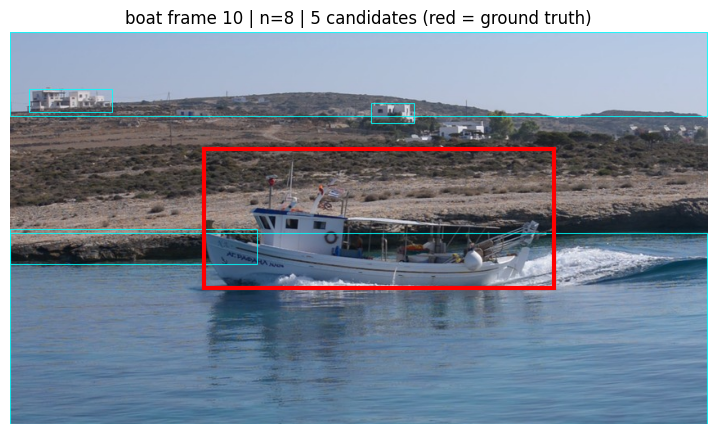


=== n=16 (256 prompts): 11 candidates


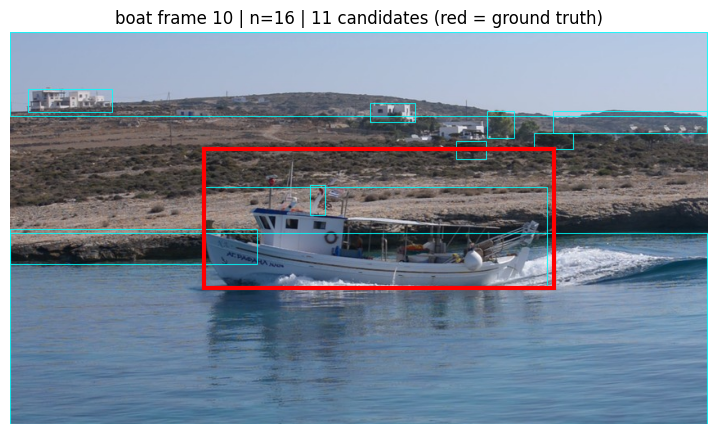


=== n=32 (1024 prompts): 15 candidates


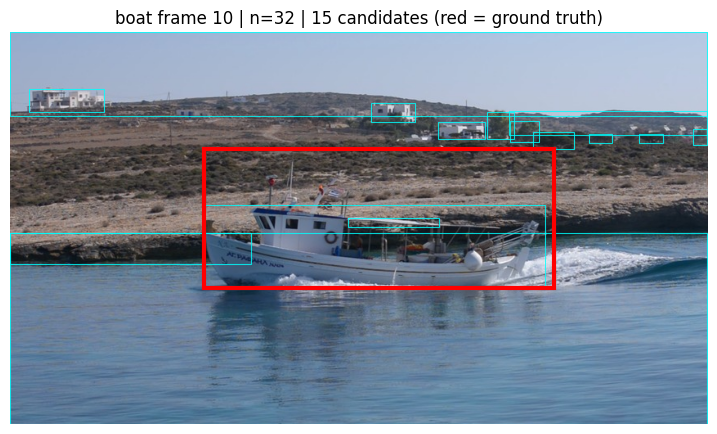


SUMMARY
 points_per_side  prompts  candidates
               8       64           5
              16      256          11
              32     1024          15


In [15]:
# Run n=8 and n=16 on one DAVIS frame and draw the boxes.

VIDEO = "boat"
FRAME = 10
GRIDS = [8, 16, 32]         # points_per_side values to compare
IOU_THR = 0.5

os.makedirs(OUT, exist_ok=True)

img, gt = load_frame(VIDEO, FRAME)
print("ground-truth objects in this frame:", list(gt.keys()))

_ = run_generator(img, 4) #warm-up for CUDA start-up

summary = []
for n in GRIDS:
    cands = run_generator(img, n)
    summary.append({"points_per_side": n,
                    "prompts": n * n,
                    "candidates": len(cands)}
                   )
    print(f"\n=== n={n} ({n*n} prompts): {len(cands)} candidates")

    draw(img,
         cands,
         gt,
         f"{VIDEO} frame {FRAME} | n={n} | {len(cands)} candidates (red = ground truth)",
         f"{OUT}/{VIDEO}_f{FRAME}_n{n}.png"
         )

print("\nSUMMARY"); print(pd.DataFrame(summary).to_string(index=False))

### Step 3.1: DINOv2
DINOv2 loads through `torch.hub` and downloads its weights the first time (kept only for this session).

In [16]:
%cd /content

/content


In [17]:
device = "cuda" if torch.cuda.is_available() else "cpu"
dino = torch.hub.load("facebookresearch/dinov2", "dinov2_vitb14").to(device).eval()
print("DINOv2 ViT-B/14 loaded on", device)

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/dinov2_vitb14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitb14_pretrain.pth


100%|██████████| 330M/330M [00:01<00:00, 199MB/s]


DINOv2 ViT-B/14 loaded on cuda


### Step 4.1: FFmpeg
FFmpeg comes pre-installed in Colab.

In [18]:
!ffmpeg -version | head -n 1

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers


### Step 4.2: Try out FFmpeg
DAVIS and MOSE come as folders of JPEG frames, not video files, so FFmpeg is not needed for sampling initially. We  will use it later to build long videos for E7. Two commands to try now:

In [19]:
#1. Convert frames -> mp4 (assuming 24 fps)
!ffmpeg -framerate 24 -i {DAVIS}/JPEGImages/480p/bear/%05d.jpg -c:v libx264 -pix_fmt yuv420p {WORK}/bear.mp4 -y

#2. Convert mp4 -> 1 frame per second
!ffmpeg -i {WORK}/bear.mp4 -vf fps=1 {WORK}/%05d.jpg

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

To play the mp4 inside Colab, run this (it reads the file from WORK):

In [20]:
from IPython.display import HTML
from base64 import b64encode
mp4 = open(f"{WORK}/bear.mp4", "rb").read()
HTML('<video width=600 controls><source src="data:video/mp4;base64,' + b64encode(mp4).decode() + '" type="video/mp4"></video>')

### Step 5.1 : Query-image / ground-truth pairs
Settings and helper functions

Build query-image / ground-truth pairs from DAVIS 2017 and split them into dev / test.

A pair = one query image (a crop of one object, taken from a RANDOM frame >= MIN_QUERY_FRAME)
         + the ground-truth boxes of that object in the rest of the video.

The search pipeline only needs: query_img + the video's frames.
The gt_boxes are for EVALUATION only (recall, precision, FPR, abstention). The search must never read them.

Note- The execution of this part is painfully slow on colab mainly due to network latency, however these are very fast on local setup.

These codes are available under scripts directory for use in local env.

I would suggest to run the code in local system to create the test pairs and dev/test split and then upload in the colab environment and directly reference that in the cells below.



In [32]:
# Settings and helpers
import json
import random
from tqdm.auto import tqdm


MIN_AREA           = 400   # an object counts as visible in a frame only if its mask has at least this many pixels
MIN_QUERY_FRAME    = 10    # the query frame is picked at random from frames >= this index
EXCLUDE_RADIUS     = 12    # frames within +-12 of the query frame are removed from the search range (near-duplicates)
QUERIES_PER_OBJECT = 1     # random query frames per object (raise it to average out the luck of one random pick)
SEED               = 0

def load_img(video, i): return np.array(Image.open(f"{IMG_DIR}/{video}/{i:05d}.jpg").convert("RGB"))

def load_ann(video, i): return np.array(Image.open(f"{ANN_DIR}/{video}/{i:05d}.png"))    # pixel value = object id

def mask_to_box(m):
    ys, xs = np.where(m)
    return [int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1]          # x0, y0, x1, y1

def masked_crop(img, mask, box, margin=0.10, bg=127):
    """Crop the object (plus 10% margin) and paint everything outside its mask gray."""
    H, W = mask.shape
    x0, y0, x1, y1 = box
    w, h = x1 - x0, y1 - y0
    x0, y0 = int(max(0, x0 - margin * w)), int(max(0, y0 - margin * h))
    x1, y1 = int(min(W, x1 + margin * w)) + 1, int(min(H, y1 + margin * h)) + 1
    crop = img[y0:y1, x0:x1].copy()
    crop[~mask[y0:y1, x0:x1]] = bg
    return Image.fromarray(crop)

In [33]:
#function to create query image / ground-truth pairs
def make_pairs(video, split):
    n = len(os.listdir(f"{IMG_DIR}/{video}"))
    anns = [load_ann(video, i) for i in range(n)]

    obj_ids = sorted({int(o) for a in anns for o in np.unique(a)} - {0, 255})   # 0 = background, 255 = void  #as many oids as there are masks

    pairs, skipped = [], []

    for oid in obj_ids:
        # frames where this object is visible, with its ground-truth box
        boxes = {i: mask_to_box(a == oid) for i, a in enumerate(anns) if (a == oid).sum() >= MIN_AREA}

        eligible = [i for i in sorted(boxes) if i >= MIN_QUERY_FRAME]
        if not eligible:
            skipped.append((video, oid, f"not visible at or after frame {MIN_QUERY_FRAME}"));
            continue

        rng = random.Random(f"{SEED}/{video}/{oid}")  # same pick every run, even if other videos change

        for q in sorted(rng.sample(eligible, min(QUERIES_PER_OBJECT, len(eligible)))):
            lo, hi = q - EXCLUDE_RADIUS, q + EXCLUDE_RADIUS
            gt = {i: b for i, b in boxes.items() if not (lo <= i <= hi)}  # visible frames inside the search range
            if not gt:
                skipped.append((video, oid, f"query {q}: object only visible near the query frame"));
                continue

            qpath = f"{PAIR_DIR}/queries/{video}__{oid}__f{q}.jpg"
            masked_crop(load_img(video, q), anns[q] == oid, boxes[q]).save(qpath, quality=95)
            pairs.append({"pair_id": f"{video}__{oid}__f{q}", "split": split, "video": video, "obj_id": oid,
                          "query_frame": q, "query_img": qpath, "query_box": boxes[q],
                          "n_frames": n, "exclude_frames": [lo, hi],  # NOT searched
                          "gt_boxes": gt})  # evaluation only; frames not listed = object absent
    return pairs, skipped

In [34]:
#function calling make_pairs and actually generate the query images
def generate_pairs():
    os.makedirs(f"{PAIR_DIR}/queries", exist_ok=True)

    # Build the pairs and split them into dev / test
    splits = {"dev":  open(f"{DAVIS}/ImageSets/2017/train.txt").read().split(),    # 60 videos
          "test": open(f"{DAVIS}/ImageSets/2017/val.txt").read().split()}      # 30 videos

    skipped_all = []
    for split, videos in splits.items():
        pairs = []
        for v in tqdm(videos, desc=split):
            p, s = make_pairs(v, split)
            pairs += p; skipped_all += s
        with open(f"{PAIR_DIR}/pairs_{split}.jsonl", "w") as f:
            for r in pairs: f.write(json.dumps(r) + "\n")
        print(split, ":", len(pairs), "pairs from", len(videos), "videos")
    print("skipped:", skipped_all)
# CHECK: this reads every annotation PNG from Drive, so it can take a few minutes.

In [35]:
#uncomment to generate pairs. Best to do in local setup.
generate_pairs()

dev:   0%|          | 0/10 [00:00<?, ?it/s]

dev : 18 pairs from 10 videos


test:   0%|          | 0/3 [00:00<?, ?it/s]

test : 5 pairs from 3 videos
skipped: []


In [36]:
# Step Reload and check a few pairs by eye
def load_pairs(split):
    out = [json.loads(l) for l in open(f"{PAIR_DIR}/pairs_{split}.jsonl")]
    for r in out: r["gt_boxes"] = {int(k): v for k, v in r["gt_boxes"].items()}   # JSON turns int keys into strings
    return out


def check_few_pairs():
    pairs_dev, pairs_test = load_pairs("dev"), load_pairs("test")
    print("dev:", len(pairs_dev), "| test:", len(pairs_test))

    assert not {p["video"] for p in pairs_dev} & {p["video"] for p in pairs_test}, "a video is in both splits!"

    for p in pairs_test[::max(1, len(pairs_test) // 3)][:3]:
        f = min(p["gt_boxes"]);
        x0, y0, x1, y1 = p["gt_boxes"][f]
        fig, ax = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1, 2.2]})
        ax[0].imshow(Image.open(p["query_img"]));
        ax[0].set_title("query image");
        ax[0].axis("off")
        ax[1].imshow(load_img(p["video"], f));
        ax[1].axis("off")
        ax[1].add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="red", lw=3))
        ax[1].set_title(f"{p['pair_id']} | target frame {f}")
        plt.show()

# CHECK: does the query crop show the same object as the red box in the later frame?

dev: 18 | test: 5


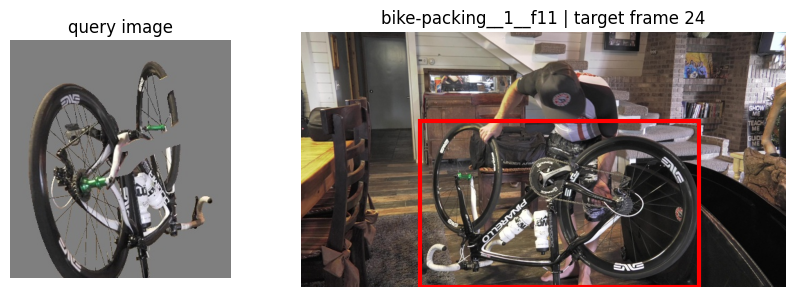

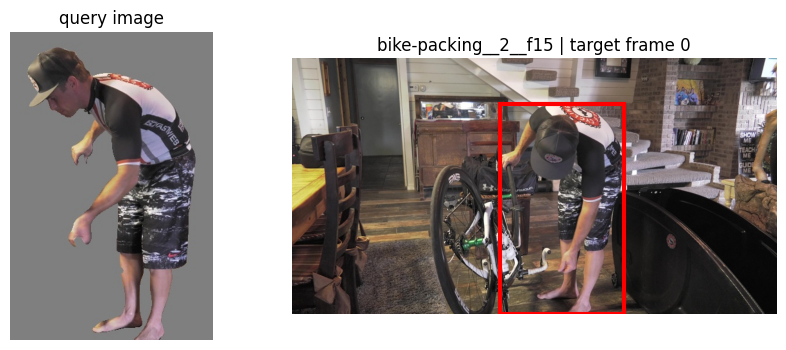

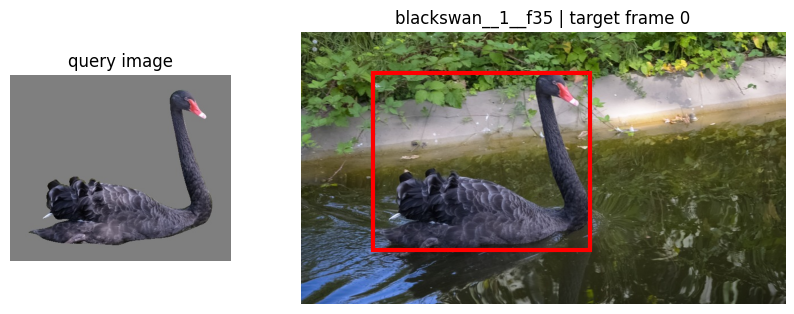

In [37]:
#uncomment to check a few pairs
check_few_pairs()

### Step: 6 Image embedding using DINO

In [38]:
#Helper functions

import torch
import torchvision.transforms as T
from PIL import Image

_PREP = T.Compose([T.Resize((224, 224)), T.ToTensor(),
                   T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])    # ImageNet mean / std

def load_dino(name="dinov2_vitb14", device=None):
    """Returns (model, device). Weights download on first use."""
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    model = torch.hub.load("facebookresearch/dinov2", name).to(device).eval()

    print("DINOv2 loaded.")
    return model, device


In [39]:
def to_square(pil, bg=127):
    """Pad to a square (gray, same as the crop background) so resizing does not squash the object."""
    s = max(pil.size)
    canvas = Image.new("RGB", (s, s), (bg, bg, bg))
    canvas.paste(pil, ((s - pil.width) // 2, (s - pil.height) // 2))
    return canvas

In [40]:
@torch.no_grad()
def embed_images(model, device, pils, batch_size=32):
    """List of PIL images -> float32 array (N, 768). Rows are unit length, so a dot product is the cosine similarity."""
    out = []
    for i in range(0, len(pils), batch_size):
        x = torch.stack([_PREP(to_square(p)) for p in pils[i:i + batch_size]]).to(device)
        out.append(torch.nn.functional.normalize(model(x), dim=-1).cpu())
    return torch.cat(out).numpy() if out else np.zeros((0, 768), dtype=np.float32)

In [41]:
def test_embedding():
    model, device = load_dino()

    pairs_test = load_pairs("dev")
    p = pairs_test[0]
    pil_image = Image.open(p["query_img"])
    z = embed_images(model, device, [pil_image])
    print("shape:", z.shape, "| length:", round(float(np.linalg.norm(z)), 3), "  (expect (1, 768) and 1.0)")

    # Same object in a later frame should be closer to the query than an object from another video
    f = min(p["gt_boxes"])
    z_same = embed_images(model, device, [masked_crop(load_img(p["video"], f), load_ann(p["video"], f) == p["obj_id"], p["gt_boxes"][f])])
    other = next(q for q in pairs_test if q["video"] != p["video"])
    z_other = embed_images(model, device, [Image.open(other["query_img"])])
    print("cosine with same object later  :", round(float(z[0] @ z_same[0]), 3))
    print("cosine with other video object :", round(float(z[0] @ z_other[0]), 3), "  (expect the first to be higher)")

In [42]:
pairs_test = load_pairs("dev")
print(len(pairs_test))
#print(pairs_test[0])
test_embedding()

18


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


DINOv2 loaded.
shape: (1, 768) | length: 1.0   (expect (1, 768) and 1.0)
cosine with same object later  : 0.931
cosine with other video object : 0.049   (expect the first to be higher)


### Step 7. Sampling frames

which frames of a video do we search?

DAVIS/MOSE already come as folders of JPEG frames,
so sampling = choosing frame indices (no FFmpeg needed).

For a real video file (e.g. the long videos in E7), FFmpeg only turns it into a folder of frames.

In [43]:
#Return the sorted frame indices to search.
#  Choose ONE way to say how dense the sampling is:
#       stride=k     keep every k-th frame (frame 0, k, 2k, ...)
#       fps=f        keep about f frames per second, i.e. stride = round(native_fps / f)
#       exclude=(lo, hi) drops frames lo..hi (inclusive), e.g. pair["exclude_frames"] around the query frame.

def sample_frames(n_frames, stride=None, fps=None, native_fps=24, exclude=None):

    if (stride is None) == (fps is None):
        raise ValueError("give exactly one of stride or fps")
    if stride is None:
        stride = max(1, round(native_fps / fps))
    frames = list(range(0, n_frames, stride))
    if exclude is not None:
        lo, hi = exclude
        frames = [i for i in frames if not (lo <= i <= hi)]
    return frames

In [44]:
def test_frame_sampling():
    frames = sample_frames(n_frames=82, stride=2, exclude=[49, 73])
    print(len(frames))
    print(frames)

In [45]:
test_frame_sampling()

29
[0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42, 44, 46, 48, 74, 76, 78, 80]


### Step 8. Define all helper functions

Note: Most of these functions are defined earlier. Defining again to keep them at one place.

In [46]:
import numpy as np
from PIL import Image

In [47]:
def load_frame(img_dir, video, i):
    return np.array(Image.open(f"{img_dir}/{video}/{i:05d}.jpg").convert("RGB"))

In [48]:
def mask_to_box(m):
    """Boolean mask -> [x0, y0, x1, y1] in pixels (top-left, bottom-right; x1 and y1 exclusive)."""
    ys, xs = np.where(m)
    return [int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1]


In [49]:
def box_iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

In [50]:
def masked_crop(img, mask, box, margin=0.10, bg=127):
    """Crop the object (plus 10% margin) and paint everything outside its mask gray.
    Query images and candidate regions MUST both go through this function (identical to make_pairs.py)."""
    H, W = mask.shape
    x0, y0, x1, y1 = box
    w, h = x1 - x0, y1 - y0
    x0, y0 = int(max(0, x0 - margin * w)), int(max(0, y0 - margin * h))
    x1, y1 = int(min(W, x1 + margin * w)) + 1, int(min(H, y1 + margin * h)) + 1
    crop = img[y0:y1, x0:x1].copy()
    crop[~mask[y0:y1, x0:x1]] = bg
    return Image.fromarray(crop)

In [51]:
def load_pairs(split):
    out = [json.loads(l) for l in open(f"{PAIR_DIR}/pairs_{split}.jsonl")]
    for r in out: r["gt_boxes"] = {int(k): v for k, v in r["gt_boxes"].items()}   # JSON turns int keys into strings
    return out

### Step 8. Define functions for SAM candidate geenration

Note- these functions are mostly derived from step 2.3

In [52]:
MIN_AREA = 400    # drop candidates smaller than this many pixels (same limit as the ground-truth objects)

In [53]:
def load_sam(checkpoint, cfg, device=None):
    """Build the SAM 2.1 model once. cfg is relative to the sam2 package (no leading 'sam2/')."""
    import torch
    from sam2.build_sam import build_sam2
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    s = build_sam2(cfg, checkpoint, device=device, apply_postprocessing=False)
    print("Sam2 loaded.")
    return s


In [54]:
def make_generator(sam, points_per_side=16, points_per_batch=32):
    """One generator per grid size. Lower points_per_batch if the GPU runs out of memory.
    kwargs go to SAM2AutomaticMaskGenerator, e.g. pred_iou_thresh, stability_score_thresh, box_nms_thresh."""
    from sam2.automatic_mask_generator import SAM2AutomaticMaskGenerator

    gn = SAM2AutomaticMaskGenerator(
        model = sam,
        points_per_side=points_per_side,
        points_per_batch=points_per_batch,
        pred_iou_thresh=0.75,          # down from 0.88 to keep harder objects
        stability_score_thresh=0.85,   # down from 0.95 to keep dynamic/blurry objects
        box_nms_thresh=0.85,           # up from 0.70 to allow nested/overlapping objects
        crop_n_layers=1,               # zoom into image crops to catch small objects
        crop_n_points_downscale_factor=2,
        min_mask_region_area=100,

        )
    print("SAM2 generator created.")
    return gn

In [55]:
def filter_candidates(raw, min_area=MIN_AREA):
    """Convert SAM output to our candidate format and drop tiny masks.
    SAM already removes low-quality masks (predicted IoU, stability score) and duplicates (box NMS).
    The box is computed from the mask with the same function as the ground-truth boxes, so the conventions match."""
    out = []
    for r in raw:
        if r["area"] < min_area:
            continue
        out.append({"mask": r["segmentation"], "box": mask_to_box(r["segmentation"]), "area": int(r["area"]),
                    "pred_iou": float(r["predicted_iou"]), "stability": float(r["stability_score"])})
    return out

In [56]:
def generate_candidates(generator, img, min_area=MIN_AREA):
    """img: RGB uint8 array (H, W, 3) -> list of candidates."""
    import torch
    with torch.inference_mode():
        raw = generator.generate(img)
    return filter_candidates(raw, min_area)

In [57]:
def candidate_crops(img, cands):
    """The images that DINOv2 will embed in step 4 (same crop recipe as the query image)."""
    return [masked_crop(img, c["mask"], c["box"]) for c in cands]

### Step 9. Test SAM candidate generation

In [58]:
import time

def test_sam_candidate_generation(param_dict, pairs):
  print(f"Starting sam candidate generation testing")
  print(f"param_dict = {param_dict}")
  print(len(pairs))

  gen = make_generator(load_sam(checkpoint=param_dict["checkpoint"], cfg=param_dict["cfg"]),
                       param_dict["grid"],
                       param_dict["points_per_batch"])

  generate_candidates(gen, load_frame(f"{IMG_DIR}", pairs[0]["video"], 0))  # warm-up, so the first timing is fair

  rows = []
  for pr in pairs:
      print(f"Pair id = {pr["pair_id"]} -------------------------------------")
      gt = {int(k): v for k, v in pr["gt_boxes"].items()}
      for i in sample_frames(pr["n_frames"], stride=param_dict["stride"], exclude=pr["exclude_frames"]):
          img = load_frame(f"{IMG_DIR}", pr["video"], i)
          if torch.cuda.is_available(): torch.cuda.synchronize()
          t0 = time.perf_counter()
          cands = generate_candidates(gen, img)
          if torch.cuda.is_available(): torch.cuda.synchronize()
          secs = time.perf_counter() - t0
          best = max((box_iou(c["box"], gt[i]) for c in cands), default=0.0) if i in gt else None   # None = object absent here
          rows.append({"query": pr["pair_id"], "frame": i, "candidates": len(cands), "secs": round(secs, 2), "best_iou": best})

  df = pd.DataFrame(rows)
  vis = df[df.best_iou.notna()]
  print(df.to_string(index=False))
  print(f"\nstride={param_dict["stride"]} grid={param_dict["grid"]}x{param_dict["grid"]}: {len(df)} frames, {df.candidates.mean():.0f} candidates/frame, "
      f"{df.secs.mean():.2f} s/frame")
  print(f"coverage (best candidate IoU >= {param_dict["iou"]} on frames where the object is visible): "
      f"{(vis.best_iou >= param_dict["iou"]).mean():.2f} over {len(vis)} frames")


In [59]:
#Create params dictionary
param_dict = {}
param_dict["checkpoint"] = f"{CKPT_DIR}/sam2.1_hiera_small.pt"
param_dict["cfg"] = "configs/sam2.1/sam2.1_hiera_s.yaml"
param_dict["grid"] = 16
param_dict["stride"] = 5
param_dict["iou"] = 0.4
param_dict["points_per_batch"] = 32

#fetch and load query image pairs
pairs = load_pairs("dev")
print(len(pairs))
print(pairs[0])


test_sam_candidate_generation(param_dict, pairs)

18
{'pair_id': 'bear__1__f61', 'split': 'dev', 'video': 'bear', 'obj_id': 1, 'query_frame': 61, 'query_img': '/content/work/out/pairs/queries/bear__1__f61.jpg', 'query_box': [109, 187, 437, 419], 'n_frames': 82, 'exclude_frames': [49, 73], 'gt_boxes': {0: [96, 214, 465, 435], 1: [95, 215, 461, 435], 2: [94, 215, 460, 434], 3: [94, 214, 451, 434], 4: [95, 213, 443, 427], 5: [96, 213, 435, 423], 6: [97, 212, 428, 420], 7: [97, 211, 426, 420], 8: [97, 211, 426, 420], 9: [98, 210, 427, 420], 10: [98, 210, 428, 420], 11: [99, 209, 431, 420], 12: [99, 210, 433, 420], 13: [101, 210, 437, 420], 14: [102, 210, 440, 421], 15: [103, 211, 444, 421], 16: [105, 211, 448, 421], 17: [107, 212, 452, 422], 18: [108, 212, 455, 422], 19: [109, 213, 460, 422], 20: [110, 213, 464, 422], 21: [111, 214, 467, 423], 22: [112, 215, 470, 423], 23: [112, 216, 472, 423], 24: [112, 217, 474, 423], 25: [111, 218, 476, 426], 26: [111, 218, 478, 434], 27: [111, 219, 480, 439], 28: [111, 220, 482, 447], 29: [111, 221, 4

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Pair id = bear__1__f61 -------------------------------------
Pair id = bmx-bumps__1__f15 -------------------------------------
Pair id = bmx-bumps__2__f49 -------------------------------------
Pair id = boat__1__f33 -------------------------------------
Pair id = boxing-fisheye__1__f26 -------------------------------------
Pair id = boxing-fisheye__2__f75 -------------------------------------
Pair id = boxing-fisheye__3__f11 -------------------------------------
Pair id = breakdance-flare__1__f40 -------------------------------------
Pair id = bus__1__f76 -------------------------------------
Pair id = car-turn__1__f35 -------------------------------------
Pair id = cat-girl__1__f37 -------------------------------------
Pair id = cat-girl__2__f31 -------------------------------------
Pair id = classic-car__1__f38 -------------------------------------
Pair id = classic-car__2__f61 -------------------------------------
Pair id = classic-car__3__f36 -------------------------------------
P

Results:

Run 1:

stride=5 grid=8x8: 209 frames, 3 candidates/frame, 0.51 s/frame

coverage (best candidate IoU >= 0.5 on frames where the object is visible): 0.19 over 193 frames

observation: object detection is very low in frames where less number of candidates are generated.

Run 2:

stride=5 grid=16x16: 209 frames, 5 candidates/frame, 1.39 s/frame

coverage (best candidate IoU >= 0.4 on frames where the object is visible): 0.21 over 193 frames


Run 3: (with SAM2 parameter tuning)

stride=5 grid=16x16: 209 frames, 28 candidates/frame, 3.83 s/frame

coverage (best candidate IoU >= 0.4 on frames where the object is visible): 0.69 over 193 frames



### Step 10. Build the index (SAM candidates + DINOv2 embeddings for every sampled frame)

At this step, we are trying to generate sam candidates, encode them and store them for each sampled frame.
The slow part, done once, with nothing depending on the query.
For each sampled frame we save every candidate's box, SAM scores and DINOv2 embeddings.
Cosine matching with a query (next step) is then instant and can be repeated for any threshold.

Where things live:
- frames: copied to the local Colab disk first (reading frames one by one from Drive is the slow part)
- cache: written to the local disk while running, and **backed up to Drive as one zip per video**, so a disconnect loses nothing

We are going to store all the index files in .npx format. Why?

Each frame stores several arrays: boxes, areas, scores and a 768-number embedding for every candidate. .npz is NumPy’s own format for exactly that.

It just has numeric array and nothing else. It keeps the dtypes and shapes, so np.load gives you the arrays back with no parsing.
Numpy is there and it requires no extra library!

#### Step 10.1: Settings

Note: This step is done for collab environment and not needed fo local setup!

NOTE: (only one-time, done on your laptop):

1. zip the frames (all directiory contating frames in JPEGImages\480p\*) so Colab can copy ONE file instead of ~6000.


2. Command to zip through Powershell-
PowerShell:  Compress-Archive -Path "<DAVIS>\JPEGImages\480p\*" -DestinationPath DAVIS_JPEG480p.zip

3. Once the zip file is created, upload DAVIS_JPEG480p.zip to Drive at data/DAVIS_JPEG480p.zip.
Without it, the cell below copies video by video (slower).

In [66]:
import shutil, zipfile, time
from pathlib import Path

LOCAL_IMG_DIR = "/content/data/JPEGImages_480p"          # local copy of the DAVIS frames
JPEG_ZIP      = f"{DRIVE_ROOT}/data/DAVIS_JPEG480p.zip"  # zip of JPEGImages/480p on Drive (see the note below)
CACHE_DIR     = "/content/cache"                         # local, fast
DRIVE_CACHE   = f"{DRIVE_ROOT}/qbi/cache"                # backup, one zip per video
INDEX_TAG     = "tuned_g16"                              # change the tag whenever the SAM settings change
STRIDE        = 5                                        # keep every 5th frame
GRID          = 16                                       # points_per_side

TAG_DIR = Path(CACHE_DIR) / INDEX_TAG
TAG_DIR.mkdir(parents=True, exist_ok=True)               # create local cache dir

Path(f"{DRIVE_CACHE}/{INDEX_TAG}").mkdir(parents=True, exist_ok=True)    #create backup cache in drive

json.dump({"grid": GRID,                                                 # stores the meta data in local cache
           "points_per_batch": POINTS_PER_BATCH,
           "stride_used_so_far": STRIDE,
           "sam": dict(pred_iou_thresh=0.75,
                       stability_score_thresh=0.85,
                       box_nms_thresh=0.85,
                       crop_n_layers=1,
                       crop_n_points_downscale_factor=2,
                       min_mask_region_area=200),
           "min_area": MIN_AREA,
           "checkpoint": checkpoint,
           "dino": "dinov2_vitb14"
           },
          open(TAG_DIR / "meta.json", "w"),
          indent=1)     # records how this cache was made


#### Step 10.2: Create local copy of each video (frames)

In [67]:
def prepare_local_frames(videos):
    os.makedirs(LOCAL_IMG_DIR, exist_ok=True)       #create local dir for video frames

    if os.path.exists(JPEG_ZIP) and not os.listdir(LOCAL_IMG_DIR):
        shutil.copy(JPEG_ZIP, "/content/DAVIS_JPEG480p.zip")                    # one big copy from Drive in local setup
        with zipfile.ZipFile("/content/DAVIS_JPEG480p.zip") as z: z.extractall(LOCAL_IMG_DIR)

    for v in videos:                                                             # fallback: copy what is still missing
        if not os.path.isdir(f"{LOCAL_IMG_DIR}/{v}"):
            shutil.copytree(f"{IMG_DIR}/{v}", f"{LOCAL_IMG_DIR}/{v}")

#### Step 10.3: Index functions
(same idea as the cache layout: cache/tag/video/frame.npz)

In [68]:
def frame_cache_path(video, frame):
    return TAG_DIR / video / f"{frame:05d}.npz"

In [69]:
#img -> arrays for this frame.
#generate_fn(img) -> candidates
#embed_fn(list of PIL) -> (N, 768)

def index_frame(img, generate_fn, embed_fn):

    cands = generate_fn(img)    #generate candidates in a given img frame

    emb = embed_fn(candidate_crops(img, cands)) if cands else np.zeros((0, 768), np.float32)   #generate embedding for each candidate

    return {"boxes": np.array([c["box"] for c in cands], dtype=np.int32).reshape(-1, 4),
            "area": np.array([c["area"] for c in cands], dtype=np.int32),
            "pred_iou": np.array([c["pred_iou"] for c in cands], dtype=np.float32),
            "stability": np.array([c["stability"] for c in cands], dtype=np.float32),
            "emb": np.asarray(emb, dtype=np.float32)
            }

In [70]:
#Load a frame from the cache, or compute and save it.
#Returns (arrays, was_computed).

def get_frame_index(video, frame, generate_fn, embed_fn):
    p = frame_cache_path(video, frame)

    if p.exists():
        return dict(np.load(p)), False

    out = index_frame(load_frame(LOCAL_IMG_DIR, video, frame), generate_fn, embed_fn)
    p.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(p, **out)
    return out, True

In [71]:
#All candidates of the given frames, stacked.
#Row j belongs to frame frame_idx[j].
def load_index(video, frames):
    parts = []

    for f in frames:
        d = dict(np.load(frame_cache_path(video, f)))
        d["frame_idx"] = np.full(len(d["boxes"]), f, dtype=np.int32)
        parts.append(d)

    return {k: np.concatenate([p[k] for p in parts]) for k in parts[0]} if parts else {}

In [72]:
# --- backup to / restore from Drive: one zip per video ---

In [73]:
def backup_video(video):
    shutil.make_archive(f"{DRIVE_CACHE}/{INDEX_TAG}/{video}", "zip", TAG_DIR / video)

def restore_videos(videos):
    for v in videos:
        z = Path(f"{DRIVE_CACHE}/{INDEX_TAG}/{v}.zip")
        if z.exists() and not (TAG_DIR / v).exists():
            with zipfile.ZipFile(z) as zf: zf.extractall(TAG_DIR / v)

#### Step 10.4: Build the index for the videos in a list of pairs

In [74]:
gen = make_generator(sam, GRID, POINTS_PER_BATCH)                        # reuses the SAM model already loaded in Step 2.3
generate_fn = lambda img: generate_candidates(gen, img)
embed_fn    = lambda pils: embed_images(dino, device, pils)              # reuses the DINOv2 already loaded in Step 3.1

def build_index(pairs, stride=STRIDE, limit_videos=None):
    videos = {}
    for r in pairs: videos[r["video"]] = r["n_frames"]
    videos = dict(list(videos.items())[:limit_videos])

    restore_videos(videos)               # pull earlier work back from Drive
    prepare_local_frames(videos)
    t0, computed = time.time(), 0
    for video, n in tqdm(videos.items(), desc="videos"):
        new = 0
        for f in sample_frames(n, stride=stride):                        # whole video; each query drops its own exclusion window later
            _, was_computed = get_frame_index(video, f, generate_fn, embed_fn)
            new += was_computed
        if new: backup_video(video)      # one Drive write per video, only if something new was computed
        computed += new
    print(f"{len(videos)} videos | {computed} frames computed | {(time.time() - t0) / 60:.1f} min")

SAM2 generator created.


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


####Step 10.5: Smoke test

Smoke test first (1 video). Check the time per frame, then run the cache a second time: it should finish in seconds.

After executing the cell, check the local cache dir -> index dir. It should have the drectory created for test video and for each sampled frame for that video, there should be an .npz file containg info about the candidates, boxes, etc..
Also, a zip file will be created for that video in drive

In [75]:
pairs_dev = load_pairs("dev")
build_index(pairs_dev, limit_videos=1)      # first run: computes (about 14 frames x ~4 s)
build_index(pairs_dev, limit_videos=1)      # second run: everything comes from the cache
v = pairs_dev[0]["video"]; n = pairs_dev[0]["n_frames"]
idx = load_index(v, sample_frames(n, stride=STRIDE))
print(v, {k: tuple(x.shape) for k, x in idx.items()})
# CHECK: 'emb' should be (total candidates, 768) and frame_idx should list the sampled frames.

videos:   0%|          | 0/1 [00:00<?, ?it/s]

1 videos | 17 frames computed | 1.2 min


videos:   0%|          | 0/1 [00:00<?, ?it/s]

1 videos | 0 frames computed | 0.0 min
bear {'boxes': (403, 4), 'area': (403,), 'pred_iou': (403,), 'stability': (403,), 'emb': (403, 768), 'frame_idx': (403,)}


#### Step 10.6: Full runs

After passing the smoke test, we run the candidate generation on full dataset.

Roughly 1 minute per video (dev has about 10 videos, test about 3).

If Colab disconnects, run the cell again: finished videos are restored from Drive and skipped.


In [76]:
#uncomment to run

#build_index(load_pairs("dev"))
#build_index(load_pairs("test"))

videos:   0%|          | 0/10 [00:00<?, ?it/s]

10 videos | 146 frames computed | 10.2 min


videos:   0%|          | 0/3 [00:00<?, ?it/s]

3 videos | 40 frames computed | 2.8 min


#### Step 10.7: How big is the cache?

In [77]:
files = list(TAG_DIR.rglob("*.npz"))
print(len(files), "frames |", round(sum(f.stat().st_size for f in files) / 1e6, 1), "MB | videos:", len({f.parent.name for f in files}))

203 frames | 16.1 MB | videos: 13


Its just 16 MB!

### Step 11. Search. match the query against the index

Cosine similarity matching

Match query image against all the candidates of a frame. Then move to another frame, Do this frame by frame to find the best match candidate.

For one pair: embed the query, take the dot product with every candidate embedding in the search range (cosine, since all vectors are unit length), and keep the best candidate. Its frame and box are what goes to the tracker.

Two parts, kept separate on purpose:
- `search_pair` finds the best candidate and records its score and margin. It does **not** use any threshold.
- `decide` applies the threshold (tau) and the margin rule (delta). Because of this split, you can try many thresholds without searching again.

Two margins are recorded:
- `margin_raw` = best score minus the second-best candidate overall. Candidates overlap a lot (nested masks, NMS 0.85), so the second-best is often the same object. This margin tends to be near zero.
- `margin` = best score minus the best candidate in the same frame that is a **different region** (box IoU < 0.5 with the winner). This is the one to use for the delta rule.

#### Step 11.1: Search functions

In [81]:
# the pairs file may hold the path of the machine that created it; keep only the file name
def resolve_query_path(p):
    return f"{PAIR_DIR}/queries/" + p["query_img"].replace("\\", "/").split("/")[-1]

def search_frames(p, stride=STRIDE):
    return sample_frames(p["n_frames"], stride=stride, exclude=p["exclude_frames"])    # same rule as when the index was built

def is_indexed(p, stride=STRIDE):
    return all(frame_cache_path(p["video"], f).exists() for f in search_frames(p, stride))


In [83]:
def search_pair(p, q_emb, stride=STRIDE):
    frames = search_frames(p, stride)
    idx = load_index(p["video"], frames)
    scores = idx["emb"] @ q_emb                                     # cosine similarity with every candidate

    r = {"pair_id": p["pair_id"], "video": p["video"], "obj_id": p["obj_id"],
         "frames_searched": len(frames), "n_candidates": len(scores)}

    if len(scores) == 0:
        return {**r, "top1_frame": None, "top1_box": None, "score": None, "margin": None, "margin_raw": None}

    top = int(np.argmax(scores))
    frame, box = int(idx["frame_idx"][top]), [int(v) for v in idx["boxes"][top]]
    s1 = float(scores[top])
    margin_raw = s1 - float(np.sort(scores)[-2]) if len(scores) > 1 else None

    same = np.where(idx["frame_idx"] == frame)[0]                  # candidates in the winner's frame
    rivals = [scores[j] for j in same if j != top and box_iou(idx["boxes"][j], box) < 0.5]
    margin = s1 - float(max(rivals)) if rivals else None           # None = nothing else competes in that frame
    return {**r, "top1_frame": frame, "top1_box": box, "score": s1, "margin": margin, "margin_raw": margin_raw}


#True = accept the match and send it to the tracker; False = abstain
def decide(r, tau, delta=0.0):
    if r["score"] is None: return False
    return r["score"] >= tau and (r["margin"] is None or r["margin"] >= delta)


#Evaluation only: is the top-1 candidate in a frame where the object is visible, with box IoU >= iou?
def is_hit(p, r, iou=0.5):
    g = p["gt_boxes"].get(r["top1_frame"])
    return g is not None and box_iou(r["top1_box"], g) >= iou

#### Step 11.2: Run the search for every dev pair whose frames are already indexed

In [84]:
pairs = [p for p in load_pairs("dev") if is_indexed(p)]
print(len(pairs), "dev pairs have a complete index (build more videos in Step 10.6 to add pairs)")

queries = embed_images(dino, device, [Image.open(resolve_query_path(p)).convert("RGB") for p in pairs])
results = [search_pair(p, q) for p, q in zip(pairs, queries)]

R = pd.DataFrame(results)
R["hit"] = [is_hit(p, r) for p, r in zip(pairs, results)]
print(f"\nRecall@1 (top-1 is the right object, box IoU >= 0.5) = {R.hit.mean():.2f} over {len(R)} pairs")
print(R.groupby("hit")[["score", "margin", "margin_raw"]].agg(["mean", "min", "max"]).round(3).to_string())
R.drop(columns=["top1_box"]).to_csv(f"{OUT}/step11_search_dev.csv", index=False)
R.drop(columns=["top1_box"]).head(10)
# CHECK: hits should have clearly higher scores than misses. That gap is what tau has to separate.

18 dev pairs have a complete index (build more videos in Step 10.6 to add pairs)

Recall@1 (top-1 is the right object, box IoU >= 0.5) = 0.83 over 18 pairs
       score               margin               margin_raw              
        mean    min    max   mean    min    max       mean    min    max
hit                                                                     
False  0.689  0.569  0.760  0.262  0.215  0.290      0.034  0.015  0.061
True   0.780  0.589  0.953  0.451  0.079  0.823      0.047  0.001  0.157


,pair_id,video,obj_id,frames_searched,n_candidates,top1_frame,score,margin,margin_raw,hit
0,bear__1__f61,bear,1,12,298,45,0.949858,0.760665,0.006403,True
1,bmx-bumps__1__f15,bmx-bumps,1,13,375,35,0.622241,0.484978,0.103438,True
2,bmx-bumps__2__f49,bmx-bumps,2,13,325,5,0.589305,0.079324,0.026633,True
3,boat__1__f33,boat,1,10,99,15,0.908542,0.620737,0.012148,True
4,boxing-fisheye__1__f26,boxing-fisheye,1,13,409,65,0.759957,0.214842,0.060823,False
5,boxing-fisheye__2__f75,boxing-fisheye,2,13,415,60,0.846286,0.204594,0.065546,True
6,boxing-fisheye__3__f11,boxing-fisheye,3,13,394,65,0.741474,0.201427,0.120342,True
7,breakdance-flare__1__f40,breakdance-flare,1,10,353,0,0.880103,0.601329,0.012763,True
8,bus__1__f76,bus,1,13,433,15,0.952574,0.823322,0.003658,True
9,car-turn__1__f35,car-turn,1,11,243,50,0.921020,0.644829,0.017275,True


#### Step 11.3: Look at a few results (green = right object, red = wrong; yellow dashed = ground truth)



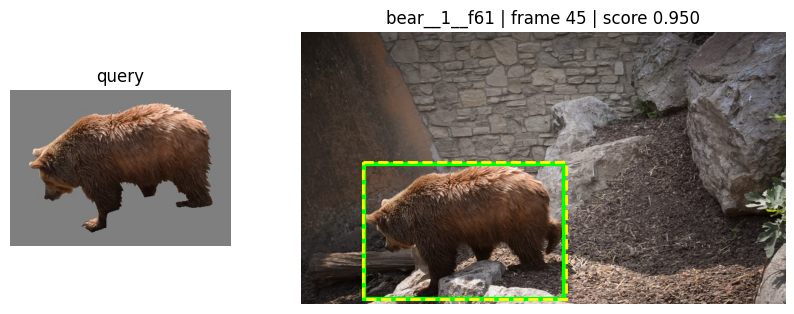

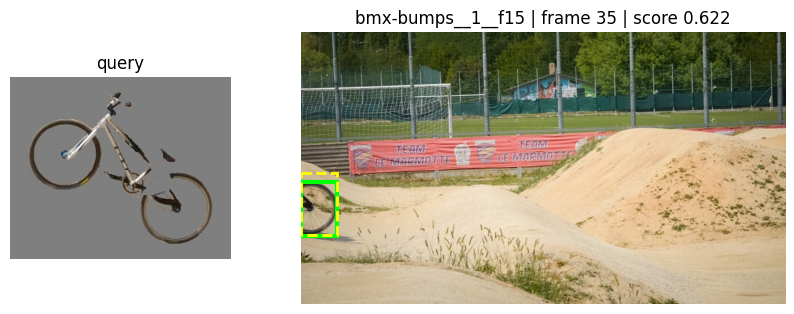

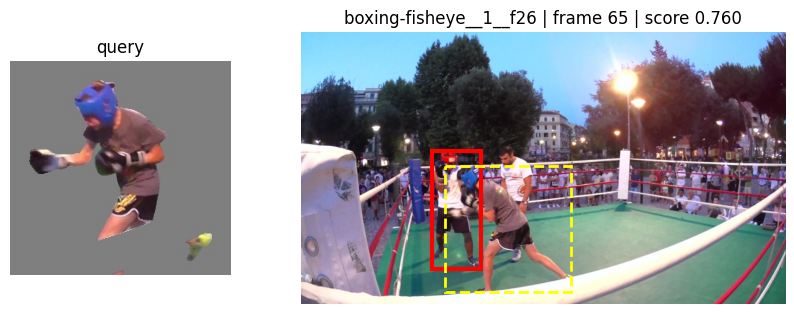

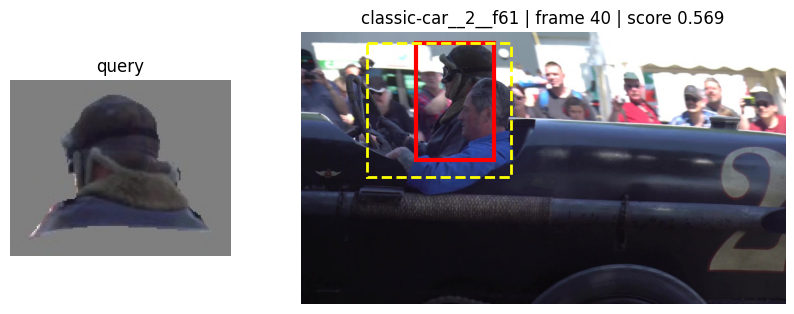

In [85]:
hits   = [i for i, h in enumerate(R.hit) if h][:2]
misses = [i for i, h in enumerate(R.hit) if not h][:2]
for i in hits + misses:
    p, r = pairs[i], results[i]
    x0, y0, x1, y1 = r["top1_box"]
    fig, ax = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1, 2.2]})
    ax[0].imshow(Image.open(resolve_query_path(p))); ax[0].set_title("query"); ax[0].axis("off")
    ax[1].imshow(load_frame(LOCAL_IMG_DIR, p["video"], r["top1_frame"])); ax[1].axis("off")
    ax[1].add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime" if R.hit[i] else "red", lw=3))
    g = p["gt_boxes"].get(r["top1_frame"])
    if g: ax[1].add_patch(patches.Rectangle((g[0], g[1]), g[2] - g[0], g[3] - g[1], fill=False, ec="yellow", lw=2, ls="--"))
    ax[1].set_title(f"{p['pair_id']} | frame {r['top1_frame']} | score {r['score']:.3f}")
    plt.show()

#### Step 11.4: Write seeds

Output for the tracker (the seed file for Manju)

One JSON line per query. `found=false` means the search abstained, so there is no seed. Pick `tau` and `delta` from the dev results; the values below are placeholders.


In [100]:
#Seed dictionary for one query, or None if the search abstains (no match accepted)
def make_seed(r, tau, delta=0.0):

    if not decide(r, tau, delta):
        return None

    seed = {
            "video": r["video"],
            "obj_id": r["obj_id"],
            "query_id": r["pair_id"],
            "frame_idx": r["top1_frame"],
            "bbox": r["top1_box"],
            "similarity": round(r["score"], 3)
            }

    if r["margin"] is not None:
        seed["margin"] = round(r["margin"], 3)      # optional: left out when nothing competes in that frame

    if r["margin_raw"] is not None:
        seed["margin_raw"] = round(r["margin_raw"], 3)

    return seed

In [103]:
#generate seed

TAU, DELTA = 0.5, 0.0          # CHECK: placeholders. Choose them from the dev results.

retrieval_result_list = [make_seed(r, TAU, DELTA) for r in results]

print(retrieval_result_list)

[{'video': 'bear', 'obj_id': 1, 'query_id': 'bear__1__f61', 'frame_idx': 45, 'bbox': [111, 232, 463, 471], 'similarity': 0.95, 'margin': 0.761, 'margin_raw': 0.006}, {'video': 'bmx-bumps', 'obj_id': 1, 'query_id': 'bmx-bumps__1__f15', 'frame_idx': 35, 'bbox': [0, 265, 64, 359], 'similarity': 0.622, 'margin': 0.485, 'margin_raw': 0.103}, {'video': 'bmx-bumps', 'obj_id': 2, 'query_id': 'bmx-bumps__2__f49', 'frame_idx': 5, 'bbox': [534, 116, 680, 319], 'similarity': 0.589, 'margin': 0.079, 'margin_raw': 0.027}, {'video': 'boat', 'obj_id': 1, 'query_id': 'boat__1__f33', 'frame_idx': 15, 'bbox': [224, 188, 647, 314], 'similarity': 0.909, 'margin': 0.621, 'margin_raw': 0.012}, {'video': 'boxing-fisheye', 'obj_id': 1, 'query_id': 'boxing-fisheye__1__f26', 'frame_idx': 65, 'bbox': [231, 209, 318, 417], 'similarity': 0.76, 'margin': 0.215, 'margin_raw': 0.061}, {'video': 'boxing-fisheye', 'obj_id': 2, 'query_id': 'boxing-fisheye__2__f75', 'frame_idx': 60, 'bbox': [233, 216, 317, 440], 'similari

### Input for the tracker pipeline: retrieval_result_list

retrieval_result_list: List of dictionary

Sample dictionary:

{
    'video': 'bear',
    'obj_id': 1,
    'query_id':
    'bear__1__f61',
    'frame_idx': 45,
    'bbox': [111, 232, 463, 471],
    'similarity': 0.95,
    'margin': 0.761,
    'margin_raw': 0.006
}

In [104]:
print(seeds)

[{'video': 'bear', 'obj_id': 1, 'query_id': 'bear__1__f61', 'frame_idx': 45, 'bbox': [111, 232, 463, 471], 'similarity': 0.95, 'margin': 0.761, 'margin_raw': 0.006}, {'video': 'bmx-bumps', 'obj_id': 1, 'query_id': 'bmx-bumps__1__f15', 'frame_idx': 35, 'bbox': [0, 265, 64, 359], 'similarity': 0.622, 'margin': 0.485, 'margin_raw': 0.103}, {'video': 'bmx-bumps', 'obj_id': 2, 'query_id': 'bmx-bumps__2__f49', 'frame_idx': 5, 'bbox': [534, 116, 680, 319], 'similarity': 0.589, 'margin': 0.079, 'margin_raw': 0.027}, {'video': 'boat', 'obj_id': 1, 'query_id': 'boat__1__f33', 'frame_idx': 15, 'bbox': [224, 188, 647, 314], 'similarity': 0.909, 'margin': 0.621, 'margin_raw': 0.012}, {'video': 'boxing-fisheye', 'obj_id': 1, 'query_id': 'boxing-fisheye__1__f26', 'frame_idx': 65, 'bbox': [231, 209, 318, 417], 'similarity': 0.76, 'margin': 0.215, 'margin_raw': 0.061}, {'video': 'boxing-fisheye', 'obj_id': 2, 'query_id': 'boxing-fisheye__2__f75', 'frame_idx': 60, 'bbox': [233, 216, 317, 440], 'similari